In [1]:
# Clustering and Multidimensional Scaling of Hybrid Similarity Search Results: Application to Illicit Drug Mass Spectra
# Melinda A. Kleczynski, Arun S. Moorthy, Anthony J. Kearsley

# two-step clustering procedure for HSS dissimilarities

### User selection

In [2]:
dataset_number = 1  # 1, 2, 3, or 4  (see Table 1)
save_outputs = False

### Packages

In [3]:
import matplotlib.pyplot as plt
import numpy as np 
import pandas as pd 

from scipy.cluster import hierarchy 
from scipy.spatial.distance import squareform  

from sklearn.metrics import silhouette_samples 

### Read data

In [4]:
# initially "unsorted" in the sense that we have not yet chosen the spectrum whose point we are restricting to the x-axis

unsorted_SSS_MFs = pd.read_csv('hitlists\\SSS' + str(dataset_number) + '.csv', header = None).to_numpy()

unsorted_asymmetric_HSS_MFs = pd.read_csv('hitlists\\HSS' + str(dataset_number) + '.csv', header = None).to_numpy()
if np.sum(np.isnan(unsorted_asymmetric_HSS_MFs)) > 0: 
    print('Caution: nan values')
unsorted_HSS_MFs = 0.5*(unsorted_asymmetric_HSS_MFs + np.transpose(unsorted_asymmetric_HSS_MFs))  # symmetrize  
unsorted_Delta = (999 - unsorted_HSS_MFs)/999

unsorted_spectra_keys = pd.read_csv('hitlists\\key' + str(dataset_number) + '.csv', usecols = ['Name', 'NIST Number']) 

n_objects = len(unsorted_spectra_keys)

### Choose spectrum to assign to x-axis and reorder to place right after query spectrum

In [5]:
farthest_spec = int(np.argmax([np.sum(np.abs(unsorted_Delta[:, 0] - unsorted_Delta[:, i])) for i in range(n_objects)]))

In [6]:
other_indices = [i for i in range(1, n_objects) if i != farthest_spec]
for_sorting = [0] + [farthest_spec] + other_indices

In [7]:
SSS_MFs = unsorted_SSS_MFs[np.ix_(for_sorting, for_sorting)]
HSS_MFs = unsorted_HSS_MFs[np.ix_(for_sorting, for_sorting)]

Delta = unsorted_Delta[np.ix_(for_sorting, for_sorting)]
spectra_keys = unsorted_spectra_keys.reindex(for_sorting).reset_index(drop = True)

### Hierarchical clustering

In [8]:
complete_hierarchical = hierarchy.linkage(squareform(Delta), method = 'complete', optimal_ordering = True) 
single_hierarchical = hierarchy.linkage(squareform(Delta), method = 'single', optimal_ordering = True) 

In [9]:
# plot suptitle for all plots 
title = 'Dataset ' + str(dataset_number) + ': ' + spectra_keys['Name'].iloc[0]

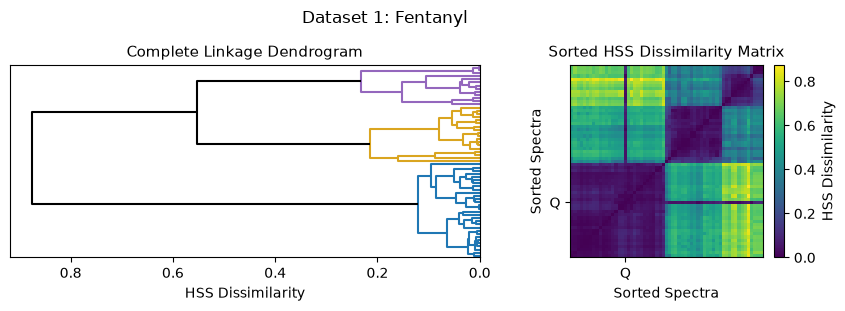

In [10]:
# plot dendrogram and sorted dissimilarity matrix 

cluster_colors = ['tab:blue', 'goldenrod', 'tab:purple']

fig, ax = plt.subplots(1, 2, figsize = (10, 2.5), width_ratios = [2, 1]) 

if dataset_number == 4:
    color_threshold = 0.75
else:
    color_threshold = 0.5 

hierarchy.set_link_color_palette(cluster_colors)
complete_dgram = hierarchy.dendrogram(complete_hierarchical, ax = ax[0], orientation = 'left', color_threshold = color_threshold, above_threshold_color = 'k')
hierarchy.set_link_color_palette(None)

ax[0].set_title('Complete Linkage Dendrogram', fontsize = 11)
ax[0].set_xlabel('HSS Dissimilarity')
ax[0].set_yticks([])

complete_leaves = complete_dgram['leaves']

cmap_plot = ax[1].imshow(Delta[np.ix_(complete_leaves, complete_leaves)], origin = 'lower', cmap = 'viridis')
ax[1].set_title('Sorted HSS Dissimilarity Matrix', fontsize = 11)  
ax[1].set_xlabel('Sorted Spectra')
ax[1].set_ylabel('Sorted Spectra')  
ax[1].set_xticks(np.where(np.array(complete_leaves) == 0)[0], ['Q'])
ax[1].set_yticks(np.where(np.array(complete_leaves) == 0)[0], ['Q'])   

cbar = plt.colorbar(cmap_plot, fraction = 0.045)  
cbar.set_label('HSS Dissimilarity')  

plt.suptitle(title, y = 1.1)

plt.show() 

### Two-step clustering procedure

In [11]:
potential_ks = np.array([k for k in range(2, 11)])

complete_sil_samples = np.zeros((len(potential_ks), n_objects))
single_sil_samples = np.zeros((len(potential_ks), n_objects))

for i in range(len(potential_ks)):

    complete_clabels = hierarchy.fcluster(complete_hierarchical, potential_ks[i], criterion = 'maxclust')
    single_clabels = hierarchy.fcluster(single_hierarchical, potential_ks[i], criterion = 'maxclust')

    complete_sil_samples[i, :] = silhouette_samples(Delta, complete_clabels, metric = 'precomputed') 
    single_sil_samples[i, :] = silhouette_samples(Delta, single_clabels, metric = 'precomputed') 

In [12]:
match_diffs = HSS_MFs[0, :] - SSS_MFs[0, :]  
query_cluster = [i for i in range(n_objects) if match_diffs[i] == 0]
other_spectra = [i for i in range(n_objects) if match_diffs[i] > 0]

In [13]:
# hierarchical clustering after removing query cluster 

noquery_complete_hierarchical = hierarchy.linkage(squareform(Delta[np.ix_(other_spectra, other_spectra)]), method = 'complete', optimal_ordering = True) 
noquery_single_hierarchical = hierarchy.linkage(squareform(Delta[np.ix_(other_spectra, other_spectra)]), method = 'single', optimal_ordering = True) 

In [14]:
# compare different numbers of clusters after removing query cluster 

noquery_complete_sil_samples = np.zeros((len(potential_ks), len(other_spectra)))
noquery_single_sil_samples = np.zeros((len(potential_ks), len(other_spectra)))

for i in range(len(potential_ks)):

    noquery_complete_clabels = hierarchy.fcluster(noquery_complete_hierarchical, potential_ks[i], criterion = 'maxclust')
    noquery_single_clabels = hierarchy.fcluster(noquery_single_hierarchical, potential_ks[i], criterion = 'maxclust')

    noquery_complete_sil_samples[i, :] = silhouette_samples(Delta[np.ix_(other_spectra, other_spectra)], noquery_complete_clabels, metric = 'precomputed') 
    noquery_single_sil_samples[i, :] = silhouette_samples(Delta[np.ix_(other_spectra, other_spectra)], noquery_single_clabels, metric = 'precomputed') 

In [15]:
# mean silhouette coefficients

noquery_complete_scores = [np.mean(noquery_complete_sil_samples[i, :]) for i in range(len(potential_ks))]
noquery_single_scores = [np.mean(noquery_single_sil_samples[i, :]) for i in range(len(potential_ks))]

In [16]:
complete_best_k = potential_ks[np.argmax(noquery_complete_scores)]
single_best_k = potential_ks[np.argmax(noquery_single_scores)]
complete_best_k == single_best_k 

np.True_

In [17]:
best_k = complete_best_k 

In [18]:
best_noquery_complete_clabels = hierarchy.fcluster(noquery_complete_hierarchical, best_k, criterion = 'maxclust')
best_noquery_single_clabels = hierarchy.fcluster(noquery_single_hierarchical, best_k, criterion = 'maxclust')

In [19]:
# check whether complete and single cluster labels are the same (up to permutation of the labels)
# for more than two clusters, may need to check other permutations of cluster labels 
# want the following to be true 

c1 = np.array_equal(best_noquery_complete_clabels, best_noquery_single_clabels)
c2 = np.array_equal(best_noquery_complete_clabels, 3-best_noquery_single_clabels)

c1 or c2

True

In [20]:
final_clabels = np.zeros(n_objects, dtype = int)
final_clabels[other_spectra] = best_noquery_complete_clabels

if save_outputs:
    np.save('TwoStepClusterLabels\\OrigDissimClabels' + str(dataset_number) + '.npy', final_clabels)

### Plots

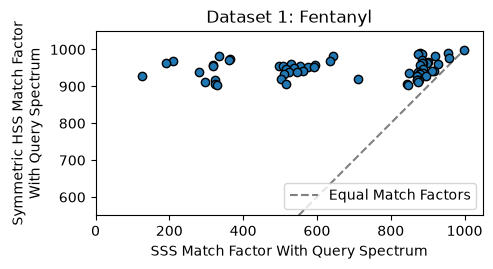

In [21]:
fig, ax = plt.subplots(figsize = (5, 5)) 

ax.scatter(SSS_MFs[0, :], HSS_MFs[0, :], edgecolors = 'k')
ax.set_aspect('equal') 

ax.plot([550, 1000], [550, 1000], color = 'gray', ls = 'dashed', zorder = 0, label = 'Equal Match Factors')
ax.legend(loc = 'lower right')

ax.set_xlim(0, 1050)
ax.set_ylim(550, 1050)

ax.set_xlabel('SSS Match Factor With Query Spectrum')
ax.set_ylabel('Symmetric HSS Match Factor\nWith Query Spectrum')  
ax.set_title(title)

plt.show()

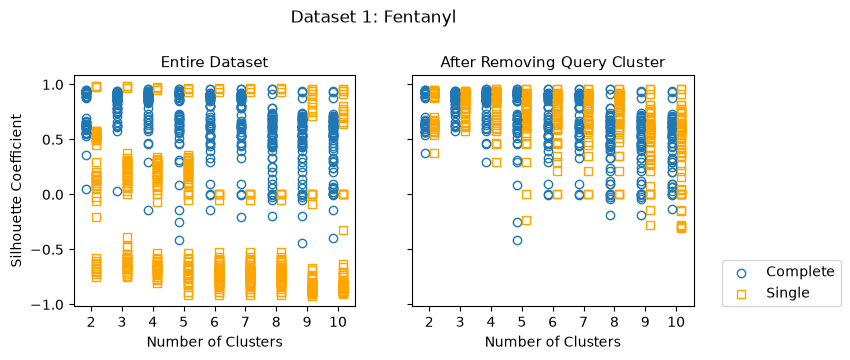

In [22]:
fig, ax = plt.subplots(1, 2, figsize = (8, 3), sharey = True) 

### left plot 

for j in range(n_objects):
  
    ax[0].scatter(potential_ks-0.15, complete_sil_samples[:, j], edgecolors = 'tab:blue', color = (0, 0, 0, 0))
    ax[0].scatter(potential_ks+0.15, single_sil_samples[:, j], edgecolors = 'orange', color = (0, 0, 0, 0), marker = 's')

### right plot 

for j in range(len(other_spectra)):
  
    ax[1].scatter(potential_ks-0.15, noquery_complete_sil_samples[:, j], edgecolors = 'tab:blue', color = (0, 0, 0, 0))
    ax[1].scatter(potential_ks+0.15, noquery_single_sil_samples[:, j], edgecolors = 'orange', color = (0, 0, 0, 0), marker = 's')

### legend 

ax[1].scatter([], [], edgecolors = 'tab:blue', color = (0, 0, 0, 0), label = 'Complete')
ax[1].scatter([], [], edgecolors = 'orange', color = (0, 0, 0, 0), label = 'Single', marker = 's')
ax[1].legend(loc = (1.1, 0))

### formatting 

for i in range(2):
    ax[i].set_xticks(potential_ks)
    ax[i].set_xlabel('Number of Clusters')

ax[0].set_ylabel('Silhouette Coefficient') 

ax[0].set_title('Entire Dataset', fontsize = 11)
ax[1].set_title('After Removing Query Cluster', fontsize = 11)

plt.suptitle(title, y = 1.1)

plt.show()

### Print additional outputs

In [23]:
# For Table 2: Comparison of Symmetric HSS Match Factor (hMFS) values in each dataset.

if dataset_number == 1:   
    match_cutoff = 900
elif dataset_number == 2:
    match_cutoff = 800 
elif dataset_number == 3: 
    match_cutoff = 800 
elif dataset_number == 4: 
    match_cutoff = 700 

print(match_cutoff, np.min(HSS_MFs[0, :]), np.min(HSS_MFs))

900 903.0 125.0


In [24]:
if dataset_number == 4: 

    k2_noquery_complete_sil_samples = noquery_complete_sil_samples[0]
    noquery_names = spectra_keys['Name'].iloc[other_spectra].to_list()
    print(noquery_names[np.argmin(k2_noquery_complete_sil_samples)])